## Import Libraries

In [4]:
import netrc
import requests
from pathlib import Path
from tqdm.auto import tqdm

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from siphon.catalog import TDSCatalog
from siphon.http_util import session_manager


## Load dataset

In [5]:
# SWOT passes available in the region 
SWOT_passes = pd.read_csv('selected_passes.csv', sep=';',
                          parse_dates=['First date', 'Last date'])
SWOT_passes

,Cycle number,Pass number,First date,Last date
0,57,42,2026-10-03 03:01:39,2026-10-03 03:01:55
1,57,57,2026-10-03 16:16:12,2026-10-03 16:16:39
2,57,320,2026-10-13 01:23:45,2026-10-13 01:24:11
3,57,335,2026-10-13 14:38:29,2026-10-13 14:38:50
4,58,42,2026-10-23 23:46:43,2026-10-23 23:46:59
5,58,57,2026-10-24 13:01:16,2026-10-24 13:01:43


In [ ]:
# Credentials from ~/.netrc
HOST = 'tds-odatis.aviso.altimetry.fr'   # must match the "machine" entry in .netrc
user, _, password = netrc.netrc().authenticators(HOST)
session_manager.set_session_options(auth=(user, password))

# Catalog URL up to "forward/" -> adjust to your server
BASE = (f'https://{HOST}/thredds/catalog/'
        'dataset-l3-swot-karin-nadir-validated/'
        'l3_lr_ssh/v3_0/Expert/forward')

out_dir = Path('data/swot_data')
out_dir.mkdir(exist_ok=True)


catalogs = {}   # one catalog per cycle, to avoid requesting it for every pass
swaths = {}

bar = tqdm(SWOT_passes.iterrows(), total=len(SWOT_passes), desc='SWOT passes')
for _, row in bar:
    cycle, pass_ = int(row['Cycle number']), int(row['Pass number'])
    label = f'{cycle:03d}/{pass_:03d}'
    bar.set_postfix_str(label)   # current pass shown next to the bar

    if cycle not in catalogs:
        try:
            catalogs[cycle] = TDSCatalog(f'{BASE}/cycle_{cycle:03d}/catalog.xml')
        except requests.HTTPError:
            catalogs[cycle] = None   # cycle not published (yet)
            bar.write(f'Cycle {cycle:03d} not available on the server')
    if catalogs[cycle] is None:
        continue

    # Find the file matching this cycle/pass
    tag = f'_{cycle:03d}_{pass_:03d}_'
    names = [n for n in catalogs[cycle].datasets if tag in n]
    if not names:
        bar.write(f'{label}: no file found')
        continue

    # Download only if not already cached locally
    name = sorted(names)[-1]
    local = out_dir / name
    if local.exists():
        status = 'cached'
    else:
        url = catalogs[cycle].datasets[name].access_urls['HTTPServer']
        r = requests.get(url, auth=(user, password))
        r.raise_for_status()   # stop here on 401/404/... instead of saving garbage
        local.write_bytes(r.content)
        status = f'downloaded ({len(r.content) / 1e6:.1f} MB)'

    ds = xr.open_dataset(local)

    # Along-track crop to the time window of interest
    t = ds['time'].load()
    mask = (t >= row['First date']) & (t <= row['Last date'])
    s = ds.isel(num_lines=mask.values)

    # Wrap longitude to -180..180 (some passes cross the Greenwich meridian)
    s = s.assign_coords(longitude=((s.longitude + 180) % 360) - 180)
    swaths[(cycle, pass_)] = s
    bar.write(f'{label}: {status}, {int(mask.sum())} lines')

print(f'\n{len(swaths)}/{len(SWOT_passes)} passes loaded')

SWOT passes:   0%|          | 0/6 [00:00<?, ?it/s]

057/042: downloaded (10.2 MB), 52 lines
057/057: downloaded (10.3 MB), 86 lines
057/320: downloaded (9.5 MB), 83 lines
057/335: downloaded (10.4 MB), 67 lines
058/042: downloaded (10.3 MB), 51 lines
058/057: downloaded (10.3 MB), 86 lines

6/6 passes loaded


## SWOT Swaths Plot

In [7]:
# Define plotting function for swath with ADT and geostrophic velocity arrows on a given axis
def plot_swath(s, ax, vmax, offset, step=5, labels=('bottom', 'left')):
    """ADT map with absolute geostrophic velocity arrows on a given axis."""
    adt = (s['ssha_filtered'] + s['mdt']).values - offset
    lon = ((s['longitude'].values + 180) % 360) - 180   # wrap to -180..180
    lat = s['latitude'].values

    pcm = ax.pcolormesh(lon, lat, adt, cmap='RdBu_r', vmin=-vmax, vmax=vmax,
                        transform=ccrs.PlateCarree())

    # Subsample arrows to keep the plot readable
    sl = (slice(None, None, step), slice(None, None, step))
    q = ax.quiver(lon[sl], lat[sl],
                  s['ugos_filtered'].values[sl], s['vgos_filtered'].values[sl],
                  scale=8, width=0.004, transform=ccrs.PlateCarree())

    ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor='0.85', zorder=2)
    ax.coastlines(resolution='10m', zorder=3)
    ax.gridlines(draw_labels=list(labels), linewidth=0.3)
    return pcm, q

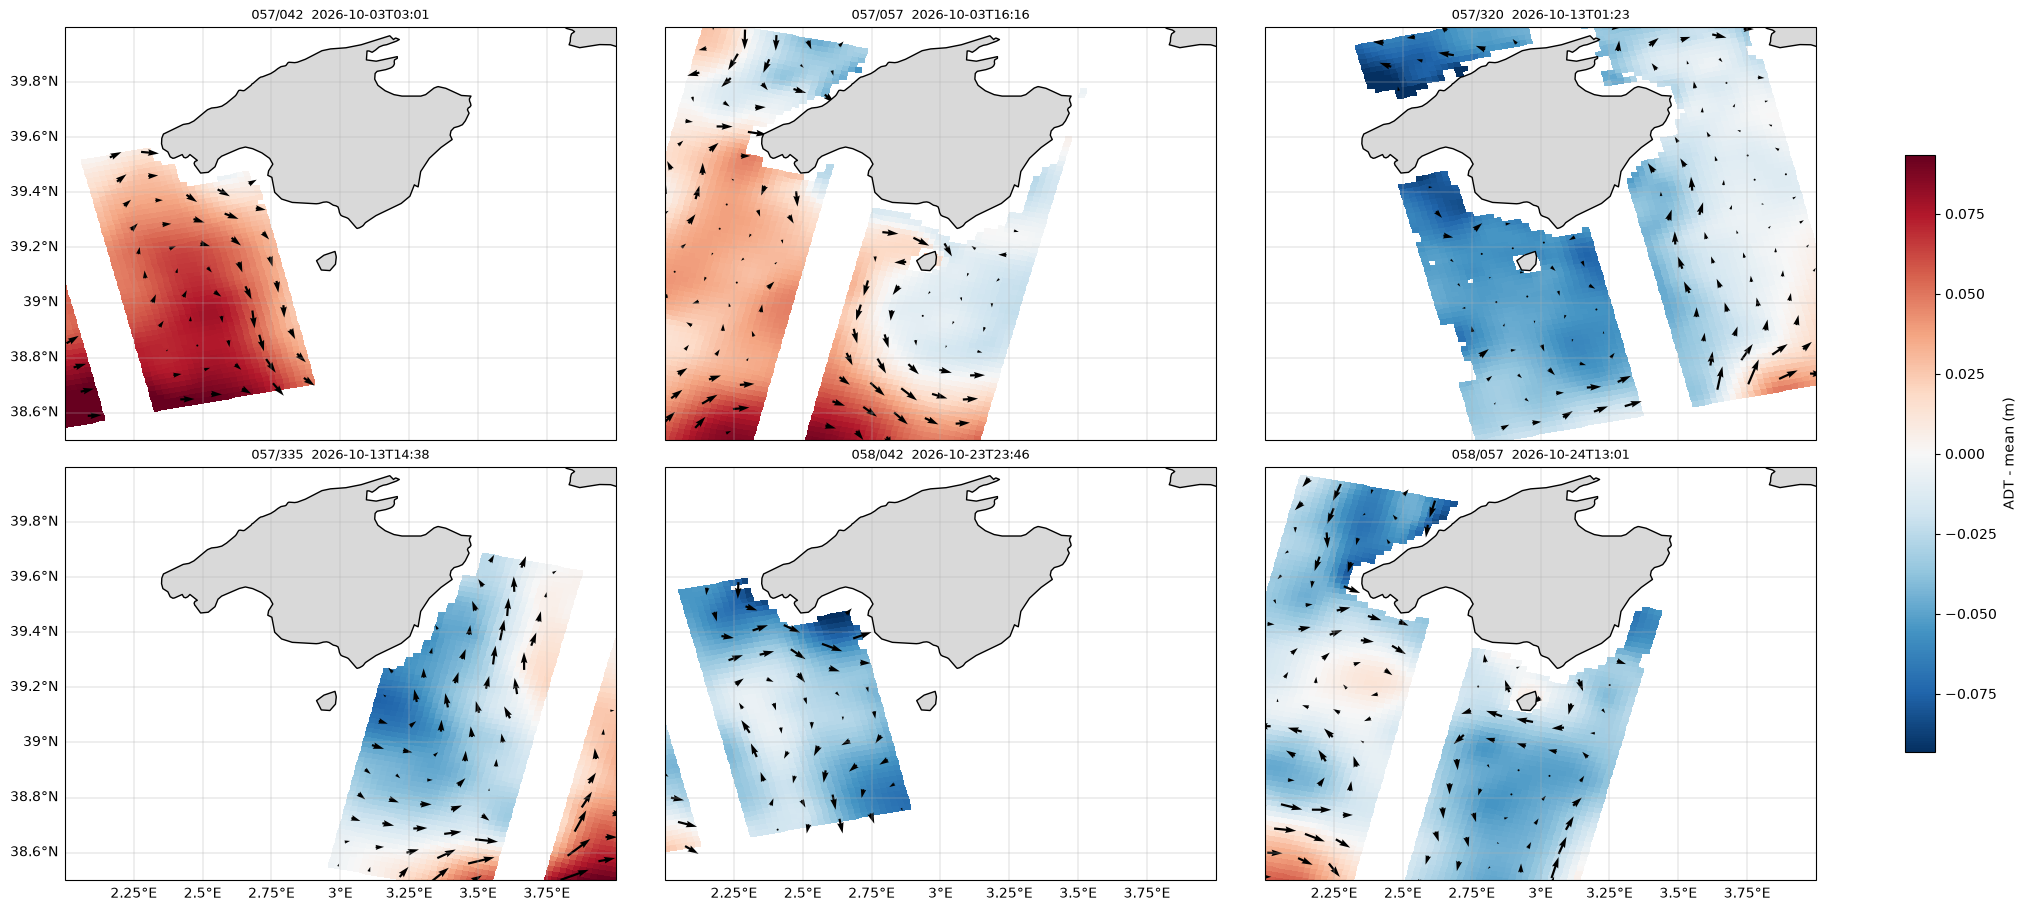

In [8]:
EXTENT = [2, 4, 38.5, 40]   # lon_min, lon_max, lat_min, lat_max

# Common reference and colour range for all passes
all_adt = np.concatenate([(s['ssha_filtered'] + s['mdt']).values.ravel()
                          for s in swaths.values()])
offset = np.nanmean(all_adt)
vmax = np.nanpercentile(np.abs(all_adt - offset), 98)

n = len(swaths)
ncols = int(np.ceil(np.sqrt(n)))
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 9), layout='constrained',
                         subplot_kw={'projection': ccrs.PlateCarree()})

for i, (ax, ((cycle, pass_), s)) in enumerate(zip(axes.flat, swaths.items())):
    # Tick labels only on the left column and bottom row
    labels = []
    if i // ncols == nrows - 1:
        labels.append('bottom')
    if i % ncols == 0:
        labels.append('left')

    pcm, q = plot_swath(s, ax, vmax, offset, labels=labels)
    ax.set_title(f'{cycle:03d}/{pass_:03d}  {str(s.time.values[0])[:16]}',
                 fontsize=9)

# Remove empty panels
for ax_empty in axes.flat[len(swaths):]:
    ax_empty.remove()

fig.colorbar(pcm, ax=axes.flat[:len(swaths)], label='ADT - mean (m)', shrink=0.7)
ax.quiverkey(q, 0.9, 1.03, 0.5, '0.5 m/s', labelpos='W', coordinates='figure')

fig.savefig('swot_all_passes.png', dpi=300, bbox_inches='tight')